**Phase 1:** Environment & Camera  |  **Phase 2:** Pose Detection & Tracking  |  **Phase 3:** Skeleton Visualization

الملفات: `camera.py`, `pose_detector.py`, `requirements.txt` 

## Phase 1: Environment Setup

In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import cv2
import matplotlib.pyplot as plt
from camera import Camera, CameraError
from pose_detector import PoseDetector

print('OpenCV:', cv2.__version__)

OpenCV: 4.11.0


### اختبار الكاميرا (Frame واحد)

Camera OK, frame shape: (480, 640, 3)


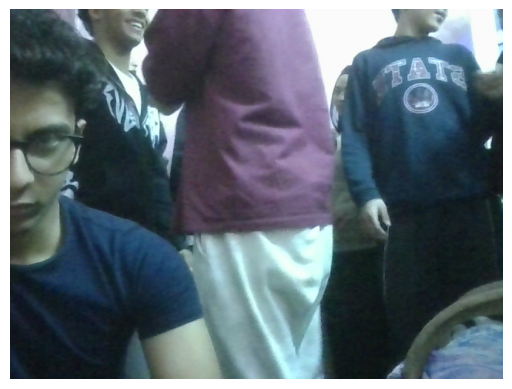

In [3]:
try:
    with Camera() as cam:
        frame = cam.read()
    print('Camera OK, frame shape:', frame.shape)
    plt.imshow(frame[:, :, ::-1]); plt.axis('off'); plt.show()
except CameraError as e:
    print('Camera error:', e)

## Phase 2: Pose Detection (على صورة واحدة)

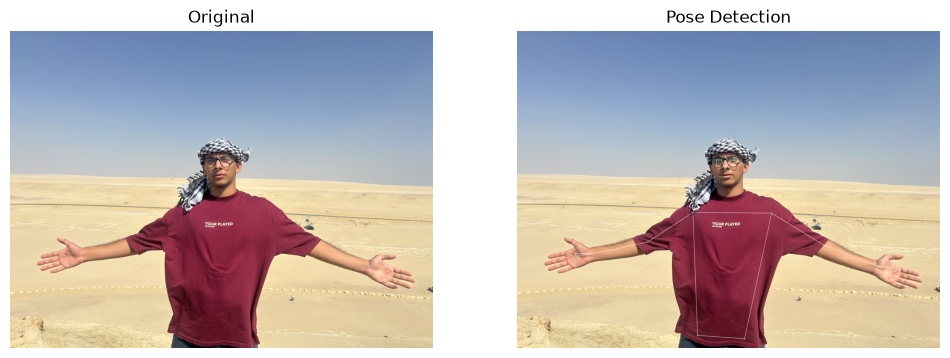

Landmarks: 33


In [4]:
detector_img = PoseDetector(static_image_mode=True, min_detection_confidence=0.5)

IMG_PATH = 'C:\\Files\\Wadi ElRayan\\IMG_3253.JPG'
image = cv2.imread(IMG_PATH)
if image is None:
    print('Image not found, skipping static test.')
else:
    out, landmarks = detector_img.process(image)
    plt.figure(figsize=[12, 6])
    plt.subplot(121); plt.imshow(image[:, :, ::-1]); plt.title('Original'); plt.axis('off')
    plt.subplot(122); plt.imshow(out[:, :, ::-1]); plt.title('Pose Detection'); plt.axis('off')
    plt.show()
    print('Landmarks:', 'No person detected' if landmarks is None else len(landmarks))

## Phase 3: Live Skeleton Visualization
اضغط **q** في نافذة الفيديو للخروج.

In [5]:
detector = PoseDetector(static_image_mode=False)

try:
    with Camera() as cam:
        while True:
            frame = cam.read()
            annotated, landmarks = detector.process(frame)
            detector.draw_info(annotated, landmarks)
            cv2.imshow('Skeleton - press q to quit', annotated)
            if cv2.waitKey(1) & 0xFF == ord('q'):
                break
except CameraError as e:
    print('Camera error:', e)
finally:
    cv2.destroyAllWindows()

## شكل البيانات اللي هتتسلم لـ Menna

In [6]:
try:
    with Camera() as cam:
        frame = cam.read()
    _, landmarks = detector.process(frame)
    if landmarks is None:
        print('No person detected')
    else:
        print(len(landmarks), 'landmarks')
        print(landmarks[0])   # NOSE
        print(landmarks[11])  # LEFT_SHOULDER
except CameraError as e:
    print('Camera error:', e)

33 landmarks
{'id': 0, 'name': 'NOSE', 'x': 0.46335068345069885, 'y': 0.4405944049358368, 'z': -0.49687623977661133, 'visibility': 0.9985896944999695, 'px': 296, 'py': 211}
{'id': 11, 'name': 'LEFT_SHOULDER', 'x': 0.7204007506370544, 'y': 0.7264692783355713, 'z': -0.5046631097793579, 'visibility': 0.9969462156295776, 'px': 461, 'py': 348}


In [7]:
detector.close()
detector_img.close()

In [ ]:
flag = True
nothing = None
print(bool(0), bool([]), nothing is None)


False True True
